# Rolling Return, Volatility and Sharpe

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Three stacked panels sharing one time axis: trailing 12-month return, annualised volatility and Sharpe ratio, each for the fund and its benchmark. A single full-period number hides regime changes; rolling windows show whether performance and risk were stable or came from one lucky stretch.

## When to use

- Check whether a strategy's edge is persistent or concentrated in one period
- Show how risk (volatility) changes across market regimes
- Monitor a live fund against its benchmark over time

## Avoid when

- Histories shorter than about three window lengths (the lines are mostly noise)
- Mixing metrics with different units on a dual y-axis (use stacked panels, as here)

## Alternatives

- Full-period metrics table
- Rolling excess return only
- Monthly returns heatmap

## Design tips

- State the window length and annualisation factor (√252 for daily, √52 for weekly data)
- Share the x-axis so events line up across panels
- Keep the benchmark gray; add a zero line to the return and Sharpe panels

## Example

Simulated daily returns of a fund and benchmark, 2015–2024, with a 252-trading-day window and a 2% risk-free rate. Simple returns; volatility = std × √252. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter

### Data

In [2]:
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
mkt = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
mkt[(dates >= "2020-02-20") & (dates <= "2020-03-23")] -= 0.012
mkt[(dates >= "2022-01-01") & (dates <= "2022-10-15")] -= 0.0011
fund = 0.00024 + 0.9 * mkt + rng.normal(0, 0.004, n)
rets = pd.DataFrame({"Fund": fund, "Benchmark": mkt}, index=dates)  # simple daily returns
freq, window, rf = 252, 252, 0.02   # obs/year, rolling window, annual risk-free rate
rets.head()

,Fund,Benchmark
2015-01-01,0.001880,0.002061
2015-01-02,0.012337,0.013092
2015-01-05,0.000317,-0.009213
2015-01-06,0.007761,0.005421
2015-01-07,-0.020201,-0.026766


### Plot

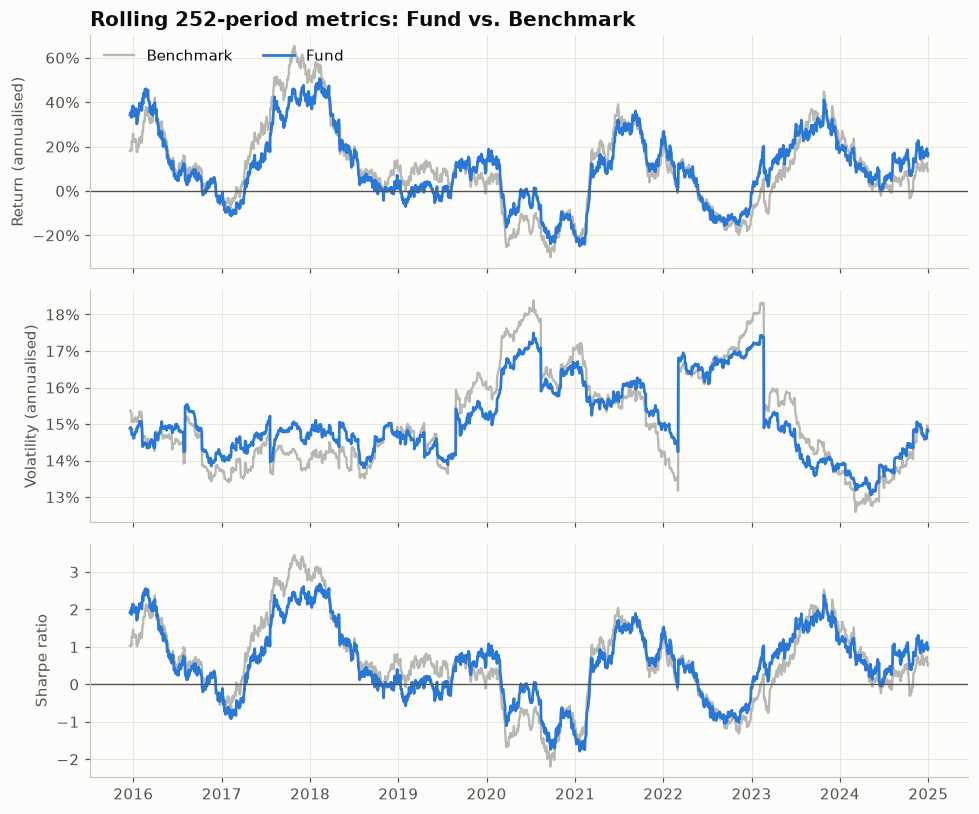

In [3]:
roll_ret = (1 + rets).rolling(window).apply(np.prod, raw=True) ** (freq / window) - 1
roll_vol = rets.rolling(window).std() * np.sqrt(freq)
roll_sharpe = (rets.rolling(window).mean() * freq - rf) / roll_vol
fund_name, bench_name = rets.columns[:2]

fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
panels = [(roll_ret, "Return (annualised)", True), (roll_vol, "Volatility (annualised)", True),
          (roll_sharpe, "Sharpe ratio", False)]
for ax, (data, label, pct) in zip(axes, panels):
    ax.plot(data.index, data[bench_name], color=GRAY, linewidth=1.5, label=bench_name)
    ax.plot(data.index, data[fund_name], color=PALETTE[0], linewidth=1.8, label=fund_name)
    if label != "Volatility (annualised)":
        ax.axhline(0, color="#52514e", linewidth=0.9)
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_ylabel(label)
axes[0].set_title(f"Rolling {window}-period metrics: {fund_name} vs. {bench_name}")
axes[0].legend(loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

## How to read it

Each panel shows a trailing one-year statistic for the date on the x-axis. Volatility spikes in the crash and in the bear market; the Sharpe panel shows when the fund's risk-adjusted return beat the benchmark (blue above gray).

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly AMZN vs an equal-weight 6-stock tech basket, 2018–2019, 26-week window

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
stocks.index = pd.to_datetime(stocks.index)
weekly = stocks.pct_change().dropna()
rets = pd.DataFrame({"AMZN": weekly["AMZN"], "Tech basket": weekly.mean(axis=1)})
freq, window, rf = 52, 26, 0.02
rets.head()

,AMZN,Tech basket
date,,
2018-01-08,0.061881,0.020246
2018-01-15,-0.008137,0.004146
2018-01-22,0.083015,0.069417
2018-01-29,0.019899,-0.024592
2018-02-05,-0.063184,-0.056030


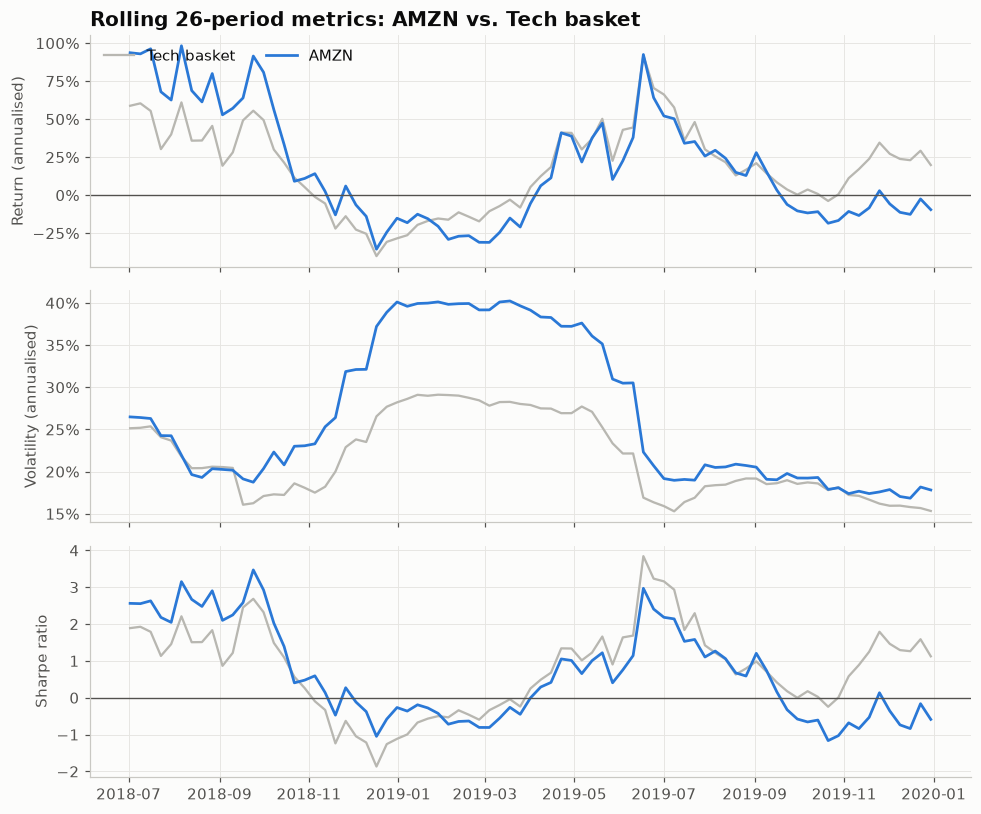

In [5]:
roll_ret = (1 + rets).rolling(window).apply(np.prod, raw=True) ** (freq / window) - 1
roll_vol = rets.rolling(window).std() * np.sqrt(freq)
roll_sharpe = (rets.rolling(window).mean() * freq - rf) / roll_vol
fund_name, bench_name = rets.columns[:2]

fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
panels = [(roll_ret, "Return (annualised)", True), (roll_vol, "Volatility (annualised)", True),
          (roll_sharpe, "Sharpe ratio", False)]
for ax, (data, label, pct) in zip(axes, panels):
    ax.plot(data.index, data[bench_name], color=GRAY, linewidth=1.5, label=bench_name)
    ax.plot(data.index, data[fund_name], color=PALETTE[0], linewidth=1.8, label=fund_name)
    if label != "Volatility (annualised)":
        ax.axhline(0, color="#52514e", linewidth=0.9)
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_ylabel(label)
axes[0].set_title(f"Rolling {window}-period metrics: {fund_name} vs. {bench_name}")
axes[0].legend(loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

---
Standalone script: [`rolling_metrics.py`](rolling_metrics.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)